## Sequential vs Parallel Execution (rubric criterion 2)

This section runs **exactly the same workload** sequentially and in parallel, and explains why the parallel speed-up is what it is.

**Workload.** The data-parallel logistic-regression training from the Data Parallelism section: gradient descent for a fixed number of steps over the 12 chunk shards in `prepared_chunks/`. At every step each shard's gradient sum is computed, the partial sums are added in shard order, and one shared `w, b` is updated.

* **Sequential**: every shard is processed in this process, one after the other (no pool at all).
* **Parallel**: the same function on the same shards, sent to a `ProcessPoolExecutor` with 1, 2, 3, 4, ... workers.

**Method.**
1. Both versions call the same function (`bench_workers.shard_gradient_timed`) and add the results in the same order, so the final `w`, `b` and every loss value must be **bit-for-bit identical**. This is checked for every run.
2. Each configuration gets a warm-up run that is not recorded (it starts the worker processes and loads the shard files into the OS file cache), then `REPEATS` timed runs. We report the mean and standard deviation of wall-clock time.
3. Speed-up `S(n) = T_seq / T(n)` and efficiency `E(n) = S(n) / n` for each worker count.
4. Each task also records which process ran it and how long it spent on file I/O and on compute. From this we split every step into: useful work on the slowest worker, waiting caused by load imbalance, scheduling/communication overhead, and the serial update in the main process.
5. Process start-up is timed separately, because one pool is reused for all steps.
6. Amdahl's law is applied twice: with the parallel fraction `p` **measured** from the sequential profile, and with an **effective** `p` fitted to the measured speed-ups. The gap between the two is the overhead.

`bench_workers.py` holds the worker functions. They must live in a `.py` file because on Windows, worker processes are *spawned* and can only run functions they can import.

In [1]:
import bench_workers   # must come first: it limits each process to one maths thread

import os, sys, platform, pickle, time
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

NOTEBOOK_START = time.perf_counter()

# ---- Settings for this section -------------------------------------------------
CHUNK_DIR = "prepared_chunks"     # written by the Data Parallelism section
STEPS = 30                        # gradient steps per timed run (fixed, no early stopping)
WARMUP_STEPS = 3                  # untimed warm-up run per configuration
REPEATS = 3                       # timed runs per configuration (mean of 3+)
ETA = 2.0                         # learning rate, same as run_gd
WORKER_COUNTS = [n for n in [1, 2, 3, 4, 6, 8] if n <= os.cpu_count()]
STARTUP_REPEATS = 3               # repeats for the process start-up measurement
HOLD_S = 0.5                      # how long each start-up probe keeps its worker busy
RESULTS_DIR = Path("results")
# ----------------------------------------------------------------------------------

RESULTS_DIR.mkdir(exist_ok=True)
chunk_ids = sorted(int(p.name[1:3]) for p in Path(CHUNK_DIR).glob("s*_train_X.npy"))
assert chunk_ids, "No chunk shards found: run the Data Parallelism section first (it writes prepared_chunks/)."
print("Worker counts to test:", WORKER_COUNTS)

Worker counts to test: [1, 2, 3, 4, 6, 8]


In [2]:
# Environment and hardware, so the timings can be interpreted and reproduced
from threadpoolctl import threadpool_info

try:
    import psutil
    physical_cores = psutil.cpu_count(logical=False)
except ImportError:
    physical_cores = None   # pip install psutil to record physical cores

print("Python     :", sys.version.split()[0], "|", platform.platform())
print("CPU        :", platform.processor() or "unknown")
print("Cores      :", os.cpu_count(), "logical |", physical_cores or "unknown", "physical")
print("Libraries  : numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)
# Every maths library must use 1 thread here, the same as in the workers. Otherwise the
# sequential run adds its partial sums differently and its last bits will not match.
for lib in threadpool_info():
    print(f"Maths lib  : {lib['internal_api']} {lib.get('version')}, threads in this process: {lib['num_threads']}")

Python     : 3.14.5 | Windows-11-10.0.26300-SP0
CPU        : Intel64 Family 6 Model 165 Stepping 3, GenuineIntel
Cores      : 12 logical | 6 physical
Libraries  : numpy 2.5.5 | pandas 3.1.1 | matplotlib 3.11.2
Maths lib  : openblas 0.3.34.237.2, threads in this process: 1


In [3]:
# The 12 shards: how much work each one is
shard_rows = [np.load(f"{CHUNK_DIR}/s{i:02d}_train_y.npy", mmap_mode="r").shape[0] for i in chunk_ids]
n_features = np.load(f"{CHUNK_DIR}/s{chunk_ids[0]:02d}_train_X.npy", mmap_mode="r").shape[1]

print(f"{len(chunk_ids)} shards | {sum(shard_rows):,} training rows | {n_features} feature(s)")
print(f"Rows per shard: {min(shard_rows):,} to {max(shard_rows):,} "
      f"(largest / average = {max(shard_rows) / np.mean(shard_rows):.3f})")
for n in WORKER_COUNTS:
    rounds = -(-len(chunk_ids) // n)          # ceiling division
    print(f"  {n} worker(s): {len(chunk_ids) / n:.2f} shards each on average, "
          f"{rounds} round(s), best possible efficiency from shard count alone = {len(chunk_ids) / (rounds * n):.2f}")

12 shards | 7,342,474 training rows | 1 feature(s)
Rows per shard: 561,780 to 658,398 (largest / average = 1.076)
  1 worker(s): 12.00 shards each on average, 12 round(s), best possible efficiency from shard count alone = 1.00
  2 worker(s): 6.00 shards each on average, 6 round(s), best possible efficiency from shard count alone = 1.00
  3 worker(s): 4.00 shards each on average, 4 round(s), best possible efficiency from shard count alone = 1.00
  4 worker(s): 3.00 shards each on average, 3 round(s), best possible efficiency from shard count alone = 1.00
  6 worker(s): 2.00 shards each on average, 2 round(s), best possible efficiency from shard count alone = 1.00
  8 worker(s): 1.50 shards each on average, 2 round(s), best possible efficiency from shard count alone = 0.75


### The shared training loop

`train` is the same loop as `run_gd`, with two changes needed for a fair benchmark:

* the pool is **passed in**, so its start-up is not counted in every run (start-up is measured separately below);
* every step records how long the shard tasks took and how long the main process spent adding the partial sums and updating `w, b` (the serial part).

With `pool=None` the shards are processed in this process (sequential). With a pool, `pool.map` returns the results **in shard order**, so the partial sums are always added in the same order as the sequential version.

In [4]:
def train(ids, out_dir, steps, pool=None, eta=ETA):
    """Fixed-step data-parallel gradient descent. Returns w, b, loss history and a per-step log."""
    k = len(ids)
    w, b = np.zeros(n_features), 0.0
    history, step_log = [], []
    for _ in range(steps):
        t0 = time.perf_counter()
        if pool is None:   # sequential: same function, same order, in this process
            out = [bench_workers.shard_gradient_timed(i, out_dir, w, b) for i in ids]
        else:              # parallel: broadcast w, b; results come back in shard order
            out = list(pool.map(bench_workers.shard_gradient_timed, ids, [out_dir] * k, [w] * k, [b] * k))
        t1 = time.perf_counter()
        G_w, G_b, loss_sum, N = (sum(v) for v in zip(*(o[0] for o in out)))   # aggregate
        w = w - eta * G_w / N                                                   # update
        b = b - eta * G_b / N
        history.append(loss_sum / N)
        t2 = time.perf_counter()
        step_log.append({"map_s": t1 - t0, "serial_s": t2 - t1, "tasks": [o[1] for o in out]})
    return w, b, history, step_log


def same_result(a, ref):
    """Bit-for-bit comparison of (w, b, history) from two runs."""
    return bool(np.array_equal(a[0], ref[0]) and a[1] == ref[1] and a[2] == ref[2])

### Sequential baseline

In [5]:
train(chunk_ids, CHUNK_DIR, WARMUP_STEPS)            # warm-up (not recorded): fills the OS file cache

seq_times, seq_logs, ref = [], [], None
for r in range(REPEATS):
    t0 = time.perf_counter()
    w, b, hist, log = train(chunk_ids, CHUNK_DIR, STEPS)
    seq_times.append(time.perf_counter() - t0)
    seq_logs += log
    if ref is None:
        ref = (w, b, hist)
    assert same_result((w, b, hist), ref), "sequential runs disagree"

print(f"Sequential, {STEPS} steps: {np.mean(seq_times):.3f}s ± {np.std(seq_times):.3f}s over {REPEATS} runs")
print(f"Final w = {ref[0]}, b = {ref[1]:.6f}, loss = {ref[2][-1]:.6f}")

Sequential, 30 steps: 16.865s ± 0.721s over 3 runs
Final w = [3.41125953], b = -0.043045, loss = 0.340270


### Parallel runs with 1, 2, 3, 4, ... workers

One pool per worker count. The warm-up run starts all the worker processes, so the timed runs measure only the training itself. Every timed run is checked against the sequential result.

In [6]:
par = {}
for n in WORKER_COUNTS:
    with ProcessPoolExecutor(max_workers=n) as pool:
        train(chunk_ids, CHUNK_DIR, WARMUP_STEPS, pool=pool)     # warm-up: starts the workers
        times, logs, matches, diffs = [], [], [], []
        for r in range(REPEATS):
            t0 = time.perf_counter()
            w, b, hist, log = train(chunk_ids, CHUNK_DIR, STEPS, pool=pool)
            times.append(time.perf_counter() - t0)
            logs += log
            matches.append(same_result((w, b, hist), ref))
            diffs.append(max(np.abs(w - ref[0]).max(), abs(b - ref[1]),
                             np.abs(np.subtract(hist, ref[2])).max()))
    par[n] = {"times": times, "logs": logs, "match": all(matches)}
    print(f"{n} worker(s): {np.mean(times):.3f}s ± {np.std(times):.3f}s | identical to sequential: {all(matches)} "
          f"(largest difference {max(diffs):.1e})")

assert all(v["match"] for v in par.values()), "a parallel run gave a different answer from the sequential run"
print(f"\nAll {REPEATS * len(WORKER_COUNTS)} parallel runs match the sequential run bit for bit "
      f"(w, b and all {STEPS} loss values).")

1 worker(s): 16.994s ± 1.153s | identical to sequential: True (largest difference 0.0e+00)
2 worker(s): 11.082s ± 0.057s | identical to sequential: True (largest difference 0.0e+00)
3 worker(s): 8.516s ± 0.120s | identical to sequential: True (largest difference 0.0e+00)
4 worker(s): 7.437s ± 0.228s | identical to sequential: True (largest difference 0.0e+00)
6 worker(s): 6.738s ± 0.179s | identical to sequential: True (largest difference 0.0e+00)
8 worker(s): 6.761s ± 0.107s | identical to sequential: True (largest difference 0.0e+00)

All 18 parallel runs match the sequential run bit for bit (w, b and all 30 loss values).


### Speed-up and efficiency

In [7]:
t_seq, sd_seq = np.mean(seq_times), np.std(seq_times)

rows = [{"config": "sequential", "workers": 1, "mean_s": t_seq, "std_s": sd_seq,
         "speedup": 1.0, "speedup_err": 0.0, "efficiency": 1.0, "matches_sequential": True}]
for n, v in par.items():
    m, sd = np.mean(v["times"]), np.std(v["times"])
    s = t_seq / m
    rows.append({"config": f"pool, {n} worker(s)", "workers": n, "mean_s": m, "std_s": sd,
                 "speedup": s, "speedup_err": s * np.hypot(sd_seq / t_seq, sd / m),
                 "efficiency": s / n, "matches_sequential": v["match"]})

bench = pd.DataFrame(rows)
bench.to_csv(RESULTS_DIR / "task2_speedup.csv", index=False)
print(bench.round(3).to_string(index=False))

           config  workers  mean_s  std_s  speedup  speedup_err  efficiency  matches_sequential
       sequential        1  16.865  0.721    1.000        0.000       1.000                True
pool, 1 worker(s)        1  16.994  1.153    0.992        0.080       0.992                True
pool, 2 worker(s)        2  11.082  0.057    1.522        0.066       0.761                True
pool, 3 worker(s)        3   8.516  0.120    1.981        0.089       0.660                True
pool, 4 worker(s)        4   7.437  0.228    2.268        0.119       0.567                True
pool, 6 worker(s)        6   6.738  0.179    2.503        0.126       0.417                True
pool, 8 worker(s)        8   6.761  0.107    2.495        0.114       0.312                True


### Where does the time go? Per-step breakdown

Each step's time is split using the timings recorded inside the tasks:

* **critical path**: the busiest worker's I/O + compute in that step. Even with zero overhead, the step cannot finish sooner than this;
* **load imbalance**: `critical path / average worker busy time` (1.00 = perfectly balanced);
* **work inflation**: total worker busy time compared with the sequential run. Above 1.00 means the *same* shard work takes longer when several workers run at once;
* **overhead**: the rest of the `pool.map` time: pickling `w, b` and the results, passing them through the inter-process pipes, task scheduling and waking the main process;
* **serial**: adding the 12 partial sums and updating `w, b` in the main process. This is the part that cannot run in parallel;
* **I/O share**: how much of the workers' busy time was spent reading shard files rather than computing.

In [8]:
def step_breakdown(logs, n_workers):
    rows = []
    for step in logs:
        busy, io, comp = {}, 0.0, 0.0
        for t in step["tasks"]:
            busy[t["pid"]] = busy.get(t["pid"], 0.0) + t["io_s"] + t["compute_s"]
            io += t["io_s"]
            comp += t["compute_s"]
        critical = max(busy.values())
        rows.append({"step_s": step["map_s"] + step["serial_s"], "map_s": step["map_s"],
                     "serial_s": step["serial_s"], "critical_s": critical,
                     "busy_total_s": io + comp,          # all workers' busy time added up
                     "io_share": io / (io + comp),
                     "imbalance": critical / ((io + comp) / n_workers),
                     "overhead_s": max(step["map_s"] - critical, 0.0),
                     "workers_used": len(busy)})
    return pd.DataFrame(rows).mean()

breakdown = pd.DataFrame(
    [step_breakdown(seq_logs, 1).rename("sequential")] +
    [step_breakdown(v["logs"], n).rename(f"{n} worker(s)") for n, v in par.items()])
breakdown["workers"] = [1] + list(par)
# Work inflation: the same 12 shards cost more CPU time in total when several workers run at
# once (they share memory bandwidth, caches and the CPU's turbo budget). 1.00 = no slowdown.
breakdown["work_inflation"] = breakdown["busy_total_s"] / breakdown.loc["sequential", "busy_total_s"]
breakdown.to_csv(RESULTS_DIR / "task2_step_breakdown.csv")

ms = breakdown[["step_s", "critical_s", "overhead_s", "serial_s", "busy_total_s"]] * 1000
print("Per step, milliseconds:")
print(ms.round(2).to_string())
print("\nRatios:")
print(breakdown[["io_share", "imbalance", "work_inflation", "workers_used"]].round(3).to_string())

Per step, milliseconds:
             step_s  critical_s  overhead_s  serial_s  busy_total_s
sequential   562.18      549.26       12.83      0.08        549.26
1 worker(s)  566.47      547.76       18.67      0.05        547.76
2 worker(s)  369.39      354.82       14.52      0.05        703.37
3 worker(s)  283.85      273.70       10.11      0.05        798.52
4 worker(s)  247.90      240.12        7.73      0.05        941.18
6 worker(s)  224.59      219.09        5.44      0.06       1253.97
8 worker(s)  225.36      219.70        5.60      0.06       1403.25

Ratios:
             io_share  imbalance  work_inflation  workers_used
sequential      0.114      1.000           1.000           1.0
1 worker(s)     0.110      1.000           0.997           1.0
2 worker(s)     0.108      1.009           1.281           2.0
3 worker(s)     0.110      1.028           1.454           3.0
4 worker(s)     0.109      1.021           1.714           4.0
6 worker(s)     0.109      1.048           2.

### Communication and data transfer

The shards are **not** sent to the workers. Each task gets only a shard id, a folder name and the current `w, b`, and reads its own shard from disk. The cell below measures how many bytes are pickled per step in each direction, compared with the size of the data the workers read themselves.

In [9]:
w0 = np.zeros(n_features)
args_bytes = sum(len(pickle.dumps((i, CHUNK_DIR, w0, 0.0))) for i in chunk_ids)
result_bytes = sum(len(pickle.dumps(bench_workers.shard_gradient_timed(i, CHUNK_DIR, w0, 0.0))) for i in chunk_ids)
shard_bytes = sum(Path(f"{CHUNK_DIR}/s{i:02d}_train_{s}.npy").stat().st_size for i in chunk_ids for s in "Xy")

print(f"Sent to workers per step     : {args_bytes / 1e3:8.1f} kB")
print(f"Returned to main per step    : {result_bytes / 1e3:8.1f} kB")
print(f"Shard data read by workers   : {shard_bytes / 1e6:8.1f} MB per step (from disk / OS cache, not pickled)")

Sent to workers per step     :      2.0 kB
Returned to main per step    :      3.3 kB
Shard data read by workers   :    117.5 MB per step (from disk / OS cache, not pickled)


### Process start-up

On Windows, every worker is a fresh Python interpreter that must start and import the modules it needs. Each probe task holds its worker for `HOLD_S` seconds, so all `n` processes must be running before the probes finish. Start-up = elapsed time − `HOLD_S`.

* **light**: the worker imports only `bench_workers` (NumPy);
* **heavy**: the worker also imports `workers.py`, which imports scikit-learn at the top. This is what the training loop in the Data Parallelism section pays, because it maps `workers.shard_gradient`.

In [10]:
def measure_startup(n, probe):
    t0 = time.perf_counter()
    pool = ProcessPoolExecutor(max_workers=n)
    pids = list(pool.map(probe, [HOLD_S] * n))
    ready = time.perf_counter() - t0 - HOLD_S
    pool.shutdown()
    return ready, len(set(pids))

startup_rows = []
for n in WORKER_COUNTS:
    for name, probe in [("light", bench_workers.ping), ("heavy", bench_workers.ping_heavy)]:
        res = [measure_startup(n, probe) for _ in range(STARTUP_REPEATS)]
        startup_rows.append({"workers": n, "imports": name,
                             "startup_s": np.mean([r[0] for r in res]),
                             "processes_seen": min(r[1] for r in res)})
startup = pd.DataFrame(startup_rows).pivot(index="workers", columns="imports", values="startup_s")
startup["extra_for_sklearn_s"] = startup["heavy"] - startup["light"]
startup.to_csv(RESULTS_DIR / "task2_startup.csv")
print(startup.round(3).to_string())
print("All requested processes started:", all(r["processes_seen"] == r["workers"] for r in startup_rows))

imports  heavy  light  extra_for_sklearn_s
workers                                   
1        2.037  0.346                1.691
2        2.135  0.354                1.780
3        2.272  0.383                1.889
4        2.474  0.415                2.059
6        3.012  0.459                2.553
8        3.522  0.531                2.991
All requested processes started: True


In [11]:
# End-to-end view: start-up + training, and how many steps it takes for parallel to pay off
seq_step = breakdown.loc["sequential", "step_s"]
rows = []
for n in WORKER_COUNTS:
    par_step = breakdown.loc[f"{n} worker(s)", "step_s"]
    saved = seq_step - par_step
    rows.append({"workers": n,
                 "startup_s": startup.loc[n, "light"],
                 "end_to_end_s": startup.loc[n, "light"] + np.mean(par[n]["times"]),
                 "sequential_s": t_seq,
                 "saved_per_step_ms": 1000 * saved,
                 "break_even_steps": startup.loc[n, "light"] / saved if saved > 0 else np.inf})
end_to_end = pd.DataFrame(rows)
print(f"For {STEPS} steps:")
print(end_to_end.round(3).to_string(index=False))

For 30 steps:
 workers  startup_s  end_to_end_s  sequential_s  saved_per_step_ms  break_even_steps
       1      0.346        17.340        16.865             -4.295               inf
       2      0.354        11.436        16.865            192.786             1.839
       3      0.383         8.899        16.865            278.324             1.377
       4      0.415         7.852        16.865            314.271             1.320
       6      0.459         7.197        16.865            337.588             1.359
       8      0.531         7.292        16.865            336.821             1.576


### Amdahl's law

Amdahl's law: if a fraction `p` of the work can run in parallel, the best possible speed-up on `n` workers is

$$S(n) = \frac{1}{(1-p) + p/n}, \qquad S_{max} = \frac{1}{1-p}.$$

* **Measured p**: from the sequential profile, the parallel part is the shard work (`map_s`) and the serial part is the aggregation and update (`serial_s`). This assumes parallelism itself costs nothing.
* **Effective p**: the `p` that best fits the speed-ups we actually measured. It includes all the overheads above, so it is lower.
* **Karp–Flatt serial fraction** `e(n) = (1/S - 1/n) / (1 - 1/n)` for each `n`. If `e` grows as `n` grows, the losses are caused by **overhead that grows with the number of workers**, not by a fixed serial part of the code.

In [12]:
def amdahl(n, p):
    return 1 / ((1 - p) + p / n)

seq_profile = breakdown.loc["sequential"]
p_measured = seq_profile["map_s"] / (seq_profile["map_s"] + seq_profile["serial_s"])

par_rows = bench[bench.config != "sequential"]
fit_rows = par_rows[par_rows.workers >= 2]
p_grid = np.linspace(0, 1, 100_001)[:, None]          # least-squares fit of p over a fine grid
S, N = fit_rows.speedup.to_numpy()[None, :], fit_rows.workers.to_numpy()[None, :]
sse = ((S - amdahl(N, p_grid)) ** 2).sum(axis=1)
p_effective = float(p_grid[int(np.argmin(sse)), 0])

amdahl_table = fit_rows[["workers", "speedup", "efficiency"]].copy()
amdahl_table["amdahl_measured_p"] = amdahl(amdahl_table.workers, p_measured)
amdahl_table["karp_flatt_e"] = (1 / amdahl_table.speedup - 1 / amdahl_table.workers) / (1 - 1 / amdahl_table.workers)
amdahl_table.to_csv(RESULTS_DIR / "task2_amdahl.csv", index=False)

print(f"Measured p  = {p_measured:.5f}  -> Amdahl limit S_max = {1 / (1 - p_measured):,.0f}x")
print(f"Effective p = {p_effective:.4f}  -> limit with today's overheads = {1 / (1 - p_effective):.2f}x")
print(amdahl_table.round(3).to_string(index=False))

Measured p  = 0.99986  -> Amdahl limit S_max = 6,923x
Effective p = 0.7098  -> limit with today's overheads = 3.45x
 workers  speedup  efficiency  amdahl_measured_p  karp_flatt_e
       2    1.522       0.761              2.000         0.314
       3    1.981       0.660              2.999         0.257
       4    2.268       0.567              3.998         0.255
       6    2.503       0.417              5.996         0.279
       8    2.495       0.312              7.992         0.315


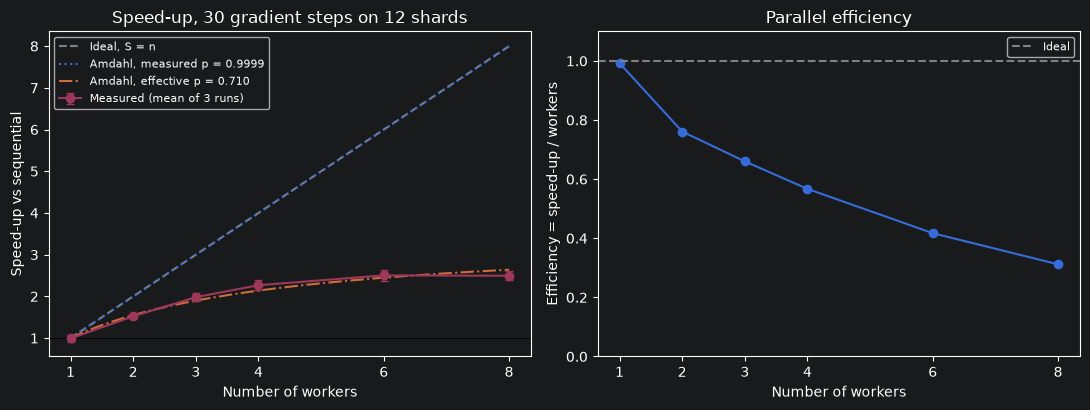

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
ns = np.array(WORKER_COUNTS)
grid = np.linspace(1, ns.max(), 200)

ax1.plot(ns, ns, "--", color="grey", label="Ideal, S = n")
ax1.plot(grid, amdahl(grid, p_measured), ":", label=f"Amdahl, measured p = {p_measured:.4f}")
ax1.plot(grid, amdahl(grid, p_effective), "-.", label=f"Amdahl, effective p = {p_effective:.3f}")
ax1.errorbar(par_rows.workers, par_rows.speedup, yerr=par_rows.speedup_err, fmt="o-", capsize=3,
             label=f"Measured (mean of {REPEATS} runs)")
ax1.axhline(1, color="black", lw=0.6)
ax1.set_xlabel("Number of workers")
ax1.set_ylabel("Speed-up vs sequential")
ax1.set_xticks(ns)
ax1.set_title(f"Speed-up, {STEPS} gradient steps on {len(chunk_ids)} shards")
ax1.legend(fontsize=8)

ax2.plot(par_rows.workers, par_rows.efficiency, "o-")
ax2.axhline(1, ls="--", color="grey", label="Ideal")
ax2.set_xlabel("Number of workers")
ax2.set_ylabel("Efficiency = speed-up / workers")
ax2.set_xticks(ns)
ax2.set_ylim(0, 1.1)
ax2.set_title("Parallel efficiency")
ax2.legend(fontsize=8)

fig.tight_layout()
fig.savefig(RESULTS_DIR / "task2_speedup.png", dpi=150, bbox_inches="tight")
plt.show()

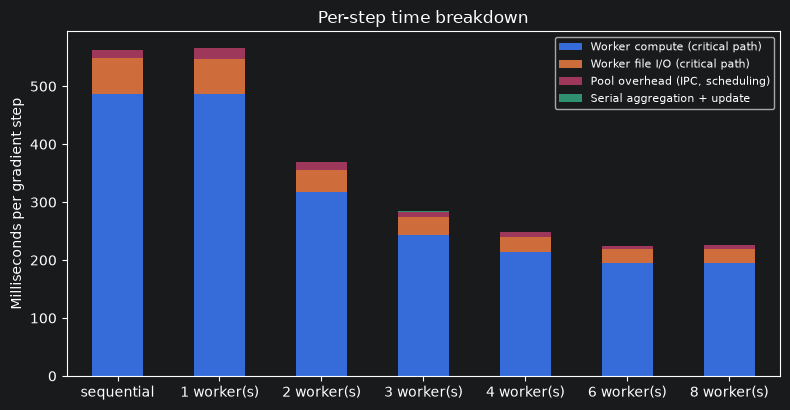

In [14]:
# Per-step time breakdown (where the time goes for each configuration)
crit = breakdown["critical_s"] * 1000
parts = pd.DataFrame({
    "Worker compute (critical path)": crit * (1 - breakdown["io_share"]),
    "Worker file I/O (critical path)": crit * breakdown["io_share"],
    "Pool overhead (IPC, scheduling)": breakdown["overhead_s"] * 1000,
    "Serial aggregation + update": breakdown["serial_s"] * 1000,
})
ax = parts.plot.bar(stacked=True, figsize=(8, 4.2), rot=0)
ax.set_ylabel("Milliseconds per gradient step")
ax.set_title("Per-step time breakdown")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task2_breakdown.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
# Key numbers in one place (the poster quotes these, so every claim can be traced back here)
best = par_rows.loc[par_rows.speedup.idxmax()]
best_name = f"{int(best.workers)} worker(s)"
print(f"Hardware: {os.cpu_count()} logical / {physical_cores or '?'} physical cores")
print(f"Workload: {STEPS} gradient steps, {len(chunk_ids)} shards, {sum(shard_rows):,} rows; {REPEATS} timed runs each")
print(f"Outputs identical to sequential in every run: {bool(bench.matches_sequential.all())}")
print(f"Sequential: {t_seq:.3f}s")
print(f"Best: {int(best.workers)} workers, {best.mean_s:.3f}s, speed-up {best.speedup:.2f}x, efficiency {best.efficiency:.2f}")
print(f"Pool with 1 worker vs sequential: {bench.loc[bench.config == 'pool, 1 worker(s)', 'speedup'].item():.2f}x "
      f"(pure cost of using a pool)")
print(f"Amdahl: measured p = {p_measured:.5f}, effective p = {p_effective:.4f}")
print(f"At {best_name}: work inflation {breakdown.loc[best_name, 'work_inflation']:.2f}x, "
      f"pool overhead {1000 * breakdown.loc[best_name, 'overhead_s']:.1f} ms of a "
      f"{1000 * breakdown.loc[best_name, 'step_s']:.1f} ms step, imbalance {breakdown.loc[best_name, 'imbalance']:.3f}")
print(f"Start-up for {WORKER_COUNTS[-1]} workers: {startup.loc[WORKER_COUNTS[-1], 'light']:.2f}s light, "
      f"{startup.loc[WORKER_COUNTS[-1], 'heavy']:.2f}s with scikit-learn imported")
print(f"I/O share of worker time (sequential): {breakdown.loc['sequential', 'io_share']:.1%}")
print(f"Section run time: {time.perf_counter() - NOTEBOOK_START:.0f}s")

Hardware: 12 logical / 6 physical cores
Workload: 30 gradient steps, 12 shards, 7,342,474 rows; 3 timed runs each
Outputs identical to sequential in every run: True
Sequential: 16.865s
Best: 6 workers, 6.738s, speed-up 2.50x, efficiency 0.42
Pool with 1 worker vs sequential: 0.99x (pure cost of using a pool)
Amdahl: measured p = 0.99986, effective p = 0.7098
At 6 worker(s): work inflation 2.28x, pool overhead 5.4 ms of a 224.6 ms step, imbalance 1.048
Start-up for 8 workers: 0.53s light, 3.52s with scikit-learn imported
I/O share of worker time (sequential): 11.4%
Section run time: 316s


### Discussion

> All numbers below come from the final run on the full dataset (12 shards, 7,342,474 training rows, 30 steps, 3 timed runs per setting) on an Intel CPU with 6 physical / 12 logical cores. Every number on the poster should be traceable to an output above.

**Same work, same answer.** Both versions call the same shard function and add the partial sums in shard order. Every parallel run gave a final `w`, `b` and all loss values bit-for-bit identical to the sequential run, so any difference in time comes from how the work was run, not from doing different work. Getting there needed one fix: the notebook's own NumPy was using one OpenBLAS thread per core, while the workers used one. A multi-threaded `X.T @ err` adds its partial sums in a different order, so the sequential result differed in the last bits. `bench_workers` now pins every process to one maths thread (`threadpoolctl`), and the environment cell prints the thread count to prove it. This is also a genuine example of *thread-count dependent library maths* for the non-determinism section.

**Speed-up.** Sequential training took 16.87 s. The best result was 2.50x with 6 workers (6.74 s, efficiency 0.42); 8 workers gave 2.50x as well (6.76 s), which is within run-to-run noise (± about 0.12x). Efficiency falls steadily as workers are added (0.76 at 2, 0.57 at 4, 0.31 at 8), and going past the 6 physical cores gives nothing more. A pool with a single worker ran at 0.99x, so simply using a pool costs very little.

**Amdahl's law.** The measured parallel fraction is p = 0.99986: adding 12 partial sums and updating two numbers takes only microseconds of each step. With that `p`, Amdahl's law predicts almost ideal speed-up (S_max ≈ 6,900x, and 7.99x at 8 workers). The effective p fitted to the measurements is only 0.710 (limit ≈ 3.45x), and the Karp–Flatt serial fraction stays between 0.26 and 0.31 for every worker count (0.314 at 2, 0.255 at 4, 0.315 at 8), about 2,000 times the 0.00014 serial fraction actually measured. So the losses are **not** caused by serial code. They come from costs that grow with the number of workers:

* **Workers slow each other down (the largest effect).** The per-step breakdown shows that pool overhead is only a few ms per step. Instead, the critical path shrinks far less than `1/n`: the same 12 shards cost 2.28x more total CPU time with 6 workers than sequentially (1.28x at 2 workers, 2.56x at 8). Each task is memory-bound element-wise work (`exp`, `log`, `clip` over ~560k–660k rows per shard), so parallel workers compete for memory bandwidth and shared cache. The CPU most likely also lowers its turbo clock when more cores are busy. (These two causes are inferred from the measurements, not measured directly.)
* **Physical cores and hyper-threading.** With 6 physical cores, workers beyond that share a core and add almost nothing. This is why the speed-up is flat between 6 and 8 workers (2.50x vs 2.50x, per-step time 224.6 ms vs 225.4 ms).
* **Load imbalance.** 12 shards divide evenly over 1, 2, 3, 4 and 6 workers, but not over 8 (12/8 needs two rounds with half the workers idle in the second). The imbalance ratio stays at or below 1.05 up to 6 workers and jumps to 1.25 at 8 workers, which cancels out the gain from the two extra workers.
* **Per-step communication and synchronisation.** Every step is a full `pool.map` round trip, and `w, b` can only be updated once all shards are done. Only about 5 kB are pickled per step (2.0 kB sent, 3.3 kB returned), so this costs 5.4 ms per step at 6 workers, small next to the 224.6 ms step (2.4%).
* **File I/O.** Each task re-reads its shard every step: 11.4% of worker time in the sequential run (117.5 MB read per step), even from the OS cache. The share stays at about 11% for every worker count, so I/O adds cost but is not what limits scaling.
* **Process start-up (one-off).** Spawning 8 workers took 0.53 s, or 3.52 s when each worker also imports scikit-learn through `workers.py` (about 3 s extra). With the light workers, parallel pays for its start-up after about 1.3–1.6 steps (1.36 steps at 6 workers), so over 30 steps 6 workers take 7.20 s end to end against 16.87 s sequentially. This explains why the short runs in the Data Parallelism section were *slower* in parallel: that code builds a new pool per run and maps `workers.shard_gradient`, so every worker imports scikit-learn. Fixes: reuse one pool, and move the `sklearn` import in `workers.py` inside `train_one_setting`.

**What would improve it.** More compute per byte of data (more features, so the matrix product dominates rather than element-wise memory traffic), keeping each shard in the worker's memory instead of re-reading it, and staying at or below the physical core count.